# Experiment 1 — Gaussian mixtures: competitiveness in the parametric regime

Figures per `docs/experiments.md`, Experiment 1 "Figures" subsection. This notebook only loads `results/exp1/results.parquet` and plots — it never recomputes (see CLAUDE.md and `docs/experiments.md` §0.4). Run `make exp1` (or `make smoke` for a fast reduced-grid pass) first if that file is missing.

**Note:** as of this run, `results/exp1/` holds the REAL (non-smoke) result: 13 grid points × 2 budget_multipliers (1.0 guaranteed-budget, 0.25 restricted-budget) × 4 algorithms × 100 reps = 10,400 rows.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

from kabc.plotting import set_style, style_for, legend_for_algorithms, savefig, ALGO_ORDER

set_style()

RESULTS_PATH = Path("../results/exp1/results.parquet")
if not RESULTS_PATH.exists():
    raise FileNotFoundError(
        f"{RESULTS_PATH} not found. Run `make exp1` (or `make smoke` for a fast "
        "reduced-grid pass) to generate it — this notebook only plots existing "
        "results, it never recomputes them."
    )
df = pd.read_parquet(RESULTS_PATH)
print(f"loaded {len(df)} rows from {RESULTS_PATH}")
print("budget_multiplier values present:", sorted(df["budget_multiplier"].unique()))

# Figs 1-3 below are the delta-PAC GUARANTEED-budget story (docs/experiments.md's
# original headline claim) -- they must use ONLY budget_multiplier=1.0 rows.
# `results/exp1/` now also contains a 0.25x restricted-budget pass (the new
# "how well do these methods degrade when queries are scarce" figure, see
# Figure 5 below) -- blending the two multipliers into one groupby(swept_value)
# mean would silently corrupt every tau/error statistic (confirmed: unif-kkm's
# tau at Delta=1 is 4x different between multipliers, since it's non-adaptive
# and just uses whatever budget it's given).
df_full = df[df["budget_multiplier"] == 1.0].copy()
df_restricted = df[df["budget_multiplier"] == 0.25].copy()
print(f"{len(df_full)} rows at budget_multiplier=1.0 (guaranteed-budget figs), "
      f"{len(df_restricted)} rows at budget_multiplier=0.25 (restricted-budget fig)")
df.head()

loaded 10400 rows from ../results/exp1/results.parquet
budget_multiplier values present: [np.float64(0.25), np.float64(1.0)]
5200 rows at budget_multiplier=1.0 (guaranteed-budget figs), 5200 rows at budget_multiplier=0.25 (restricted-budget fig)


,exp_id,family,algorithm,rep,seed,swept_param,swept_value,budget_cap,budget_multiplier,s_star,...,Delta,sigma,sigma_B,a,ring_radius,ring_noise,data_dir,arms_per_prototype,min_ratings,mean_gap_tol
0,1,gaussian_mixture,kabc,0,1000,Delta,1.0,608809,1.0,0.373831,...,1.0,1.0,None,None,None,None,None,None,None,None
1,1,gaussian_mixture,kabc,1,1001,Delta,1.0,608809,1.0,0.373831,...,1.0,1.0,None,None,None,None,None,None,None,None
2,1,gaussian_mixture,kabc,2,1002,Delta,1.0,608809,1.0,0.373831,...,1.0,1.0,None,None,None,None,None,None,None,None
3,1,gaussian_mixture,kabc,3,1003,Delta,1.0,608809,1.0,0.373831,...,1.0,1.0,None,None,None,None,None,None,None,None
4,1,gaussian_mixture,kabc,4,1004,Delta,1.0,608809,1.0,0.373831,...,1.0,1.0,None,None,None,None,None,None,None,None


## Figure 1 (headline): log τ vs log Δ, all methods, with theoretical slope overlay

Main plot of the Δ sweep (base N, K, d held fixed). Dashed grey line shows the theoretical scaling `τ ∝ s*^{-2}` (Theorem 3.1), anchored to KABC's curve at the median Δ so only the *slope* is being compared, not the absolute constant. `s*` is read directly from the `s_star` column already stored in the results (computed once by `scripts/run_experiment.py` when sizing `budget_cap`) — not recomputed here.

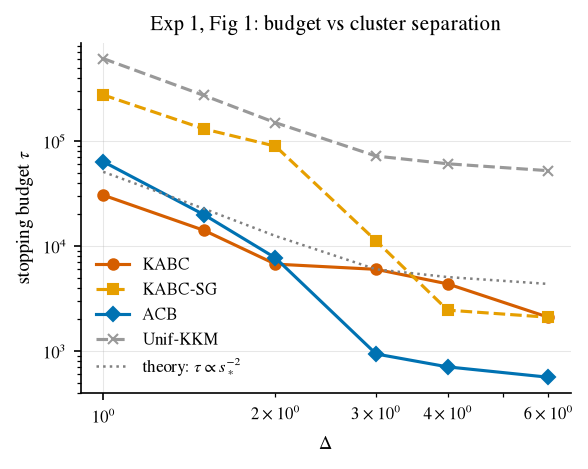

In [2]:
delta_df = df_full[df_full["swept_param"] == "Delta"].copy()

fig, ax = plt.subplots(figsize=(4, 3.2))

for algo in [a for a in ALGO_ORDER if a in delta_df["algorithm"].unique()]:
    g = delta_df[delta_df["algorithm"] == algo].groupby("swept_value")["tau"].mean().sort_index()
    ax.plot(g.index, g.values, **style_for(algo))

# theoretical slope overlay: tau_theory ~ s_star^-2, anchored to kabc at the
# median Delta so only the slope (not the constant) is compared
s_star_by_delta = delta_df.groupby("swept_value")["s_star"].mean().sort_index()
kabc_tau = delta_df[delta_df["algorithm"] == "kabc"].groupby("swept_value")["tau"].mean().sort_index()
anchor_delta = s_star_by_delta.index[len(s_star_by_delta) // 2]
anchor_const = kabc_tau.loc[anchor_delta] * (s_star_by_delta.loc[anchor_delta] ** 2)
theory_tau = anchor_const * s_star_by_delta ** -2
ax.plot(
    s_star_by_delta.index, theory_tau.values, color="grey", linestyle=":", linewidth=1.2,
    label=r"theory: $\tau \propto s_*^{-2}$",
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$\Delta$")
ax.set_ylabel(r"stopping budget $\tau$")
ax.set_title("Exp 1, Fig 1: budget vs cluster separation")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, frameon=False)
fig.tight_layout()
savefig(fig, "exp1_fig1_tau_vs_delta", fig_dir="../results/figures")
plt.show()

## Figure 2: τ box plots vs d

Does the nonparametric price grow with ambient dimension?

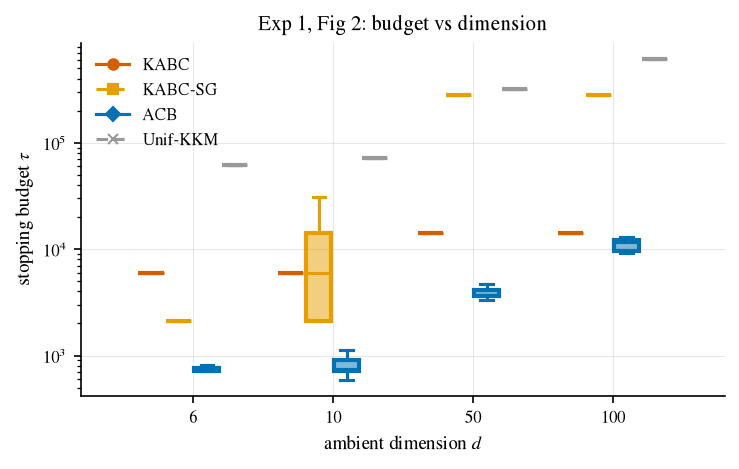

In [3]:
d_df = df_full[df_full["swept_param"] == "d"].copy()
d_values = sorted(d_df["swept_value"].unique())
algos = [a for a in ALGO_ORDER if a in d_df["algorithm"].unique()]

fig, ax = plt.subplots(figsize=(5, 3.2))
width = 0.8 / len(algos)
positions = np.arange(len(d_values))

import matplotlib.colors as mcolors
from kabc.plotting import ALGO_COLORS, ALGO_LABELS

for i, algo in enumerate(algos):
    data = [d_df[(d_df["swept_value"] == d) & (d_df["algorithm"] == algo)]["tau"].values for d in d_values]
    color = ALGO_COLORS[algo]
    bp = ax.boxplot(
        data,
        positions=positions + (i - (len(algos) - 1) / 2) * width,
        widths=width * 0.9,
        patch_artist=True,
        showfliers=False,
    )
    for box in bp["boxes"]:
        # NOTE: box.set_alpha() would fade the EDGE too, not just the fill
        # -- for a near-zero-height box (common at smoke scale: low
        # within-rep variance in tau), the edge is the only thing that
        # actually conveys the box's presence, so it must stay fully
        # opaque. Only the face gets a translucent RGBA facecolor.
        box.set_facecolor(mcolors.to_rgba(color, alpha=0.5))
        box.set_edgecolor(color)
        box.set_linewidth(2.0)
    for element in ("whiskers", "caps"):
        for artist in bp[element]:
            artist.set_color(color)
            artist.set_linewidth(1.5)
    for median in bp["medians"]:
        # NOT black: for a near-zero-height box (Q1~=Q3, common at smoke
        # scale), the median line sits exactly on top of the box edge and
        # is drawn LAST, so a black median was painting over the
        # correctly-colored edge entirely, making every low-variance box
        # look like a plain black line regardless of algorithm. Matching
        # the algo color keeps it correct regardless of z-order/overlap.
        median.set_color(color)
        median.set_linewidth(1.5)

ax.set_xticks(positions)
ax.set_xticklabels([str(int(d)) for d in d_values])
ax.set_yscale("log")
ax.set_xlabel("ambient dimension $d$")
ax.set_ylabel(r"stopping budget $\tau$")
ax.set_title("Exp 1, Fig 2: budget vs dimension")
legend_for_algorithms(ax, algos, frameon=False)
fig.tight_layout()
savefig(fig, "exp1_fig2_tau_vs_d", fig_dir="../results/figures")
plt.show()

## Figure 3: empirical error per method per config

Validates `error <= delta` (0.05) everywhere, per `docs/experiments.md` §0.4.

In [4]:
error_table = (
    df_full.groupby(["swept_param", "swept_value", "algorithm"])["error"]
    .mean()
    .rename("empirical_error")
    .reset_index()
    .sort_values(["swept_param", "swept_value", "algorithm"])
)
error_table["exceeds_delta"] = error_table["empirical_error"] > 0.05
error_table

,swept_param,swept_value,algorithm,empirical_error,exceeds_delta
0,Delta,1.0,acb,0.12,True
1,Delta,1.0,kabc,0.00,False
2,Delta,1.0,kabc-sg,0.97,True
3,Delta,1.0,unif-kkm,0.00,False
4,Delta,1.5,acb,0.11,True
5,Delta,1.5,kabc,0.00,False
6,Delta,1.5,kabc-sg,0.84,True
7,Delta,1.5,unif-kkm,0.00,False
8,Delta,2.0,acb,0.13,True
9,Delta,2.0,kabc,0.00,False


### Figure 3b: error rate heatmap (both budget regimes)

**Heatmap chosen over a grouped bar chart:** this data spans 3 sweeps (Δ: 6
values, d: 4, N: 3 — 13 grid points) × 2 budget multipliers × 4 algorithms =
up to 104 (grid point, multiplier, algorithm) cells. A grouped bar chart at
that density either needs 104 bars in one axis (unreadable) or ~26 small
multi-bar groups (still cramped and hard to scan for "which cells are bad").
A heatmap encodes the same 104 numbers as one grid, lets color instantly
flag anything above δ=0.05, and scales far better with this many categories
along two axes (grid point × algorithm) than bars do. The underlying exact
numbers are also always available in the Figure 3 table above and the
`heatmap_data` DataFrame printed below — this is a visual on top of that
table, not a replacement for it.

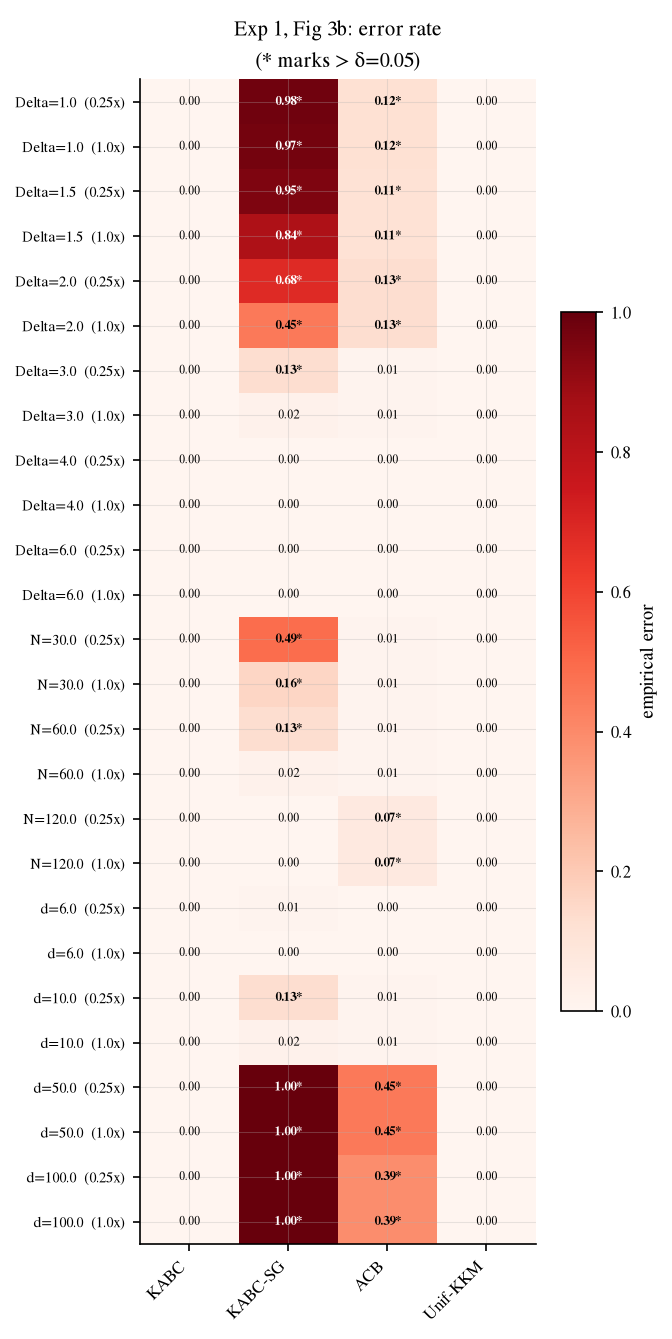

In [5]:
heatmap_data = (
    df.groupby(["swept_param", "swept_value", "budget_multiplier", "algorithm"])["error"]
    .mean()
    .rename("error_rate")
    .reset_index()
)
heatmap_data["row_label"] = (
    heatmap_data["swept_param"] + "=" + heatmap_data["swept_value"].astype(str)
    + "  (" + heatmap_data["budget_multiplier"].map({1.0: "1.0x", 0.25: "0.25x"}) + ")"
)
row_order = (
    heatmap_data[["swept_param", "swept_value", "budget_multiplier", "row_label"]]
    .drop_duplicates()
    .sort_values(["swept_param", "swept_value", "budget_multiplier"])["row_label"]
    .tolist()
)
col_order = [a for a in ALGO_ORDER if a in heatmap_data["algorithm"].unique()]

pivot = heatmap_data.pivot(index="row_label", columns="algorithm", values="error_rate").reindex(
    index=row_order, columns=col_order
)

fig, ax = plt.subplots(figsize=(4.5, 9))
im = ax.imshow(pivot.values, cmap="Reds", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(col_order)))
ax.set_xticklabels([ALGO_LABELS[a] for a in col_order], rotation=45, ha="right")
ax.set_yticks(range(len(row_order)))
ax.set_yticklabels(row_order, fontsize=7)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        val = pivot.values[i, j]
        if np.isnan(val):
            continue
        exceeds = val > 0.05
        ax.text(
            j, i, f"{val:.2f}" + ("*" if exceeds else ""),
            ha="center", va="center", fontsize=6,
            color="white" if val > 0.5 else "black",
            fontweight="bold" if exceeds else "normal",
        )
ax.set_title("Exp 1, Fig 3b: error rate\n(* marks > δ=0.05)", fontsize=10)
fig.colorbar(im, ax=ax, label="empirical error", shrink=0.6)
fig.tight_layout()
savefig(fig, "exp1_fig3b_error_heatmap", fig_dir="../results/figures")
plt.show()

## Figure 4 (appendix): theoretical vs calibrated constants

Requires comparing a calibrated-constant run (`c_cal` from `configs/calibration.yaml`, used by `make exp1`) against a separate theoretical-constant run (`c=1`, uncalibrated). The latter is not part of the standard `make exp1` output, so this panel can only be built once such a comparison run exists.

In [6]:
calib_path = Path("../configs/calibration.yaml")
c_cal = yaml.safe_load(calib_path.read_text())["c_cal"] if calib_path.exists() else None

if c_cal is None or all(v is None for v in c_cal.values()):
    print(
        "c_cal has not been calibrated yet (configs/calibration.yaml has null values).\n"
        "Run `make calibrate` first, then re-run `make exp1`, to populate this comparison.\n"
        "Skipping Figure 4 — nothing to plot from the current results."
    )
else:
    print(
        "c_cal is calibrated (", c_cal, ") but results/exp1/results.parquet only contains "
        "the calibrated-constant run. Figure 4 needs a second, theoretical-constant (c=1) "
        "run to compare against — generate one (e.g. a dedicated `make exp1-theory` target "
        "or a separate results file) before this panel can be built here; this notebook "
        "will not recompute it silently."
    )

c_cal is calibrated ( {'kabc': {'value': 0.103516, 'calibration_set_error': 0.0, 'held_out_error': 0.0}, 'kabc-sg': {'value': 0.121094, 'calibration_set_error': 0.0, 'held_out_error': 0.0}, 'acb': {'value': 0.658984, 'calibration_set_error': 0.02, 'held_out_error': 0.01}, 'tas-fw': {'value': None, 'calibration_set_error': None, 'held_out_error': None}} ) but results/exp1/results.parquet only contains the calibrated-constant run. Figure 4 needs a second, theoretical-constant (c=1) run to compare against — generate one (e.g. a dedicated `make exp1-theory` target or a separate results file) before this panel can be built here; this notebook will not recompute it silently.


## Figure 5: restricted-budget degradation — ARI vs Δ at budget_cap = 0.25×

**New addition, complementary to Figure 1, not a replacement for it.** Figure 1
tells the δ-PAC "guaranteed budget" story: how much budget each method
*needs* to certify its answer. This figure asks the applied question instead:
*how well does each method do if it can't afford that much?* Real deployments
of active clustering often can't spend the full guaranteed-budget amount, so
this measures graceful degradation under a hard 4x cut, using the same Δ axis
as Figure 1 so the two are directly comparable side by side (same x-axis,
different y-axis and budget regime) rather than requiring the reader to
cross-reference separate sweeps.

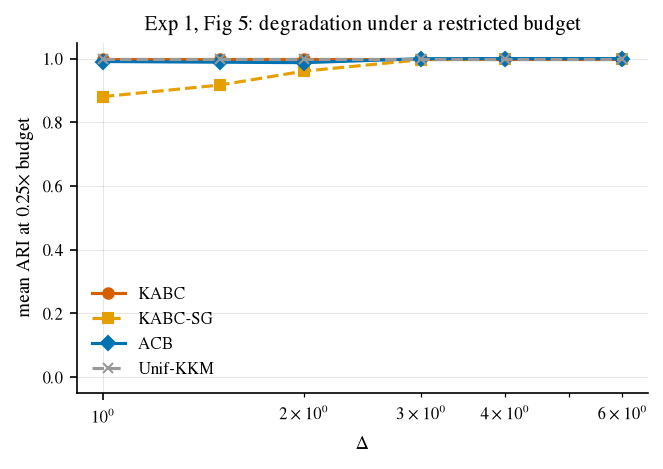

Restricted-budget (0.25x) mean ARI by swept_value (Delta):
swept_value       1.0       1.5       2.0       3.0  4.0  6.0
algorithm                                                    
kabc         1.000000  1.000000  1.000000  1.000000  1.0  1.0
kabc-sg      0.880491  0.917002  0.960449  0.996285  1.0  1.0
acb          0.990729  0.988558  0.987124  0.999496  1.0  1.0
unif-kkm     1.000000  1.000000  1.000000  1.000000  1.0  1.0

Restricted-budget (0.25x) stopped_rate by algorithm, Delta sweep:
swept_value   1.0   1.5   2.0   3.0  4.0  6.0
algorithm                                    
kabc         1.00  1.00  1.00  1.00  1.0  1.0
kabc-sg      0.02  0.05  0.32  0.87  1.0  1.0
acb          1.00  1.00  1.00  1.00  1.0  1.0
unif-kkm     1.00  1.00  1.00  1.00  1.0  1.0


In [7]:
delta_restricted = df_restricted[df_restricted["swept_param"] == "Delta"].copy()

fig, ax = plt.subplots(figsize=(4.5, 3.2))
for algo in [a for a in ALGO_ORDER if a in delta_restricted["algorithm"].unique()]:
    g = delta_restricted[delta_restricted["algorithm"] == algo].groupby("swept_value")["ari"].mean().sort_index()
    ax.plot(g.index, g.values, **style_for(algo))

ax.set_xscale("log")
ax.set_xlabel(r"$\Delta$")
ax.set_ylabel("mean ARI at 0.25× budget")
ax.set_ylim(-0.05, 1.05)
ax.set_title("Exp 1, Fig 5: degradation under a restricted budget")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, "exp1_fig5_restricted_budget_ari_vs_delta", fig_dir="../results/figures")
plt.show()

algos_present = [a for a in ALGO_ORDER if a in delta_restricted["algorithm"].unique()]
print("Restricted-budget (0.25x) mean ARI by swept_value (Delta):")
print(delta_restricted.groupby(["algorithm", "swept_value"])["ari"].mean().unstack().reindex(algos_present).to_string())
print()
print("Restricted-budget (0.25x) stopped_rate by algorithm, Delta sweep:")
print(delta_restricted.groupby(["algorithm", "swept_value"])["stopped"].mean().unstack().reindex(algos_present).to_string())

## Figure 2b: τ vs N

Companion to Figure 2 (τ vs d) — does budget scale reasonably with the number
of arms N? Same visual standard as Figures 1/2 (shared `ALGO_COLORS`/`style_for`
from `kabc.plotting`).

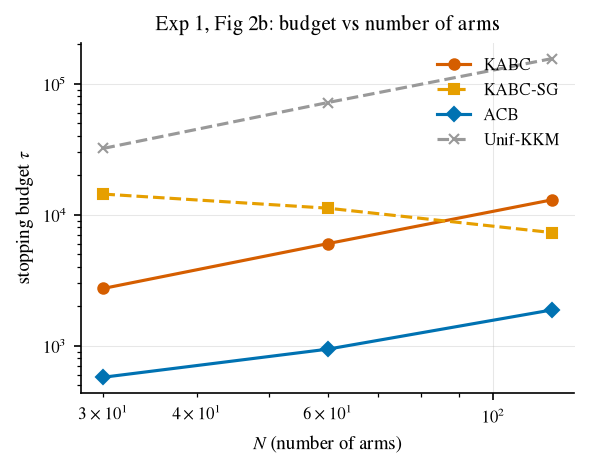

In [8]:
n_df = df_full[df_full["swept_param"] == "N"].copy()

fig, ax = plt.subplots(figsize=(4, 3.2))
for algo in [a for a in ALGO_ORDER if a in n_df["algorithm"].unique()]:
    g = n_df[n_df["algorithm"] == algo].groupby("swept_value")["tau"].mean().sort_index()
    ax.plot(g.index, g.values, **style_for(algo))

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("$N$ (number of arms)")
ax.set_ylabel(r"stopping budget $\tau$")
ax.set_title("Exp 1, Fig 2b: budget vs number of arms")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, "exp1_fig2b_tau_vs_N", fig_dir="../results/figures")
plt.show()

## Figure 5b/5c: restricted-budget degradation — ARI vs d and vs N at 0.25× budget

Figure 5 covered the Δ sweep only. Same restricted-budget question, extended
to the other two swept dimensions (d, N), each broken down BY the actual
swept value (not collapsed to one average) so it's visible whether ARI stays
uniformly high or degrades specifically at harder grid points (e.g. d=100).
The exact per-value numbers are printed under each plot, not just shown
visually, since that's what determines any honest restricted-budget claim.

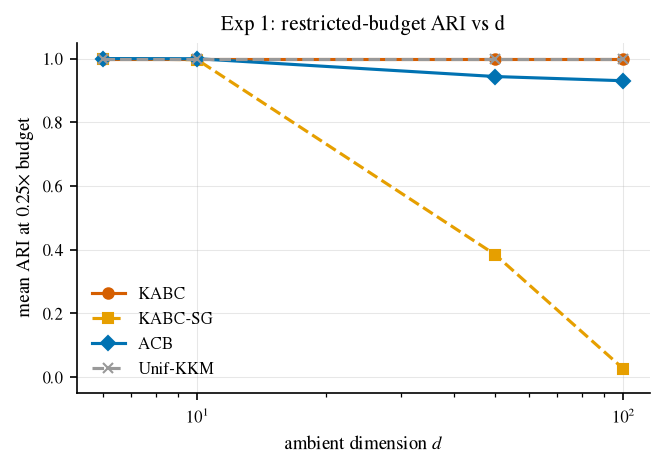

Restricted-budget (0.25x) mean ARI by swept_value (d):
swept_value     6.0       10.0      50.0      100.0
algorithm                                          
kabc         1.000000  1.000000  1.000000  1.000000
kabc-sg      0.999752  0.996285  0.384781  0.026193
acb          1.000000  0.999496  0.943607  0.930362
unif-kkm     1.000000  1.000000  1.000000  1.000000



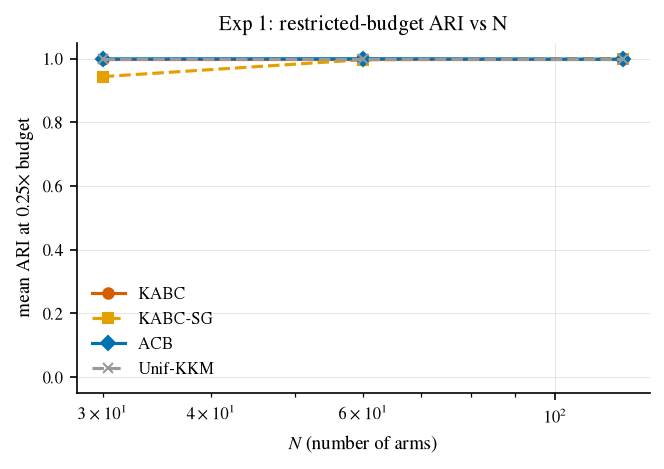

Restricted-budget (0.25x) mean ARI by swept_value (N):
swept_value     30.0      60.0      120.0
algorithm                                
kabc         1.000000  1.000000  1.000000
kabc-sg      0.943346  0.996285  1.000000
acb          0.998982  0.999496  0.997998
unif-kkm     1.000000  1.000000  1.000000



In [9]:
def restricted_ari_figure(swept_param, xlabel, fig_name, log_x=True):
    sub = df_restricted[df_restricted["swept_param"] == swept_param].copy()
    algos_present = [a for a in ALGO_ORDER if a in sub["algorithm"].unique()]

    fig, ax = plt.subplots(figsize=(4.5, 3.2))
    for algo in algos_present:
        g = sub[sub["algorithm"] == algo].groupby("swept_value")["ari"].mean().sort_index()
        ax.plot(g.index, g.values, **style_for(algo))
    if log_x:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("mean ARI at 0.25× budget")
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(f"Exp 1: restricted-budget ARI vs {swept_param}")
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    savefig(fig, fig_name, fig_dir="../results/figures")
    plt.show()

    breakdown = sub.groupby(["algorithm", "swept_value"])["ari"].mean().unstack().reindex(algos_present)
    print(f"Restricted-budget (0.25x) mean ARI by swept_value ({swept_param}):")
    print(breakdown.to_string())
    print()
    return breakdown


ari_by_d = restricted_ari_figure("d", "ambient dimension $d$", "exp1_fig5b_restricted_budget_ari_vs_d")
ari_by_N = restricted_ari_figure("N", "$N$ (number of arms)", "exp1_fig5c_restricted_budget_ari_vs_N")